# 02 — Linear / Ridge regression implemented from scratch

Model code: `src/scratch_linear.py` (NumPy only).

## Mathematical formulation
For observation $i$ (a country-year), $\mathbf{x}_i\in\mathbb{R}^{p}$ ($p=11$ standardized variables):
$$\hat y_i = \mathbf{w}^\top\mathbf{x}_i + b$$

**Objective function** (MSE + L2 penalty, the bias is not penalized):
$$J(\mathbf{w},b)=\frac{1}{2n}\sum_{i=1}^{n}\left(\mathbf{w}^\top\mathbf{x}_i+b-y_i\right)^2+\frac{\alpha}{2}\lVert\mathbf{w}\rVert^2$$

**Gradient** ($\mathbf{r}=X\mathbf{w}+b\mathbf{1}-\mathbf{y}$):
$$\nabla_{\mathbf{w}}J=\frac1n X^\top\mathbf{r}+\alpha\mathbf{w},\qquad \frac{\partial J}{\partial b}=\frac1n\mathbf{1}^\top\mathbf{r}$$

**Optimization.**
* *Gradient descent*: $\theta_{k+1}=\theta_k-\eta\nabla J(\theta_k)$. $J$ is convex and quadratic with Hessian $H=\tilde X^\top\tilde X/n+\alpha D$; GD converges if and only if $0<\eta<2/\lambda_{\max}(H)$. Stopping: $|J_k-J_{k-1}|<10^{-10}$ or a maximum number of iterations.
* *Mini-batch SGD*: gradient estimated on $B$ observations drawn without replacement, decaying step $\eta_e=\eta_0/(1+\delta e)$.
* *Normal equations* (check): $\nabla J=0 \iff (\tilde X^\top\tilde X/n+\alpha D)\,\theta=\tilde X^\top\mathbf{y}/n$, solved exactly.

**Why this model?** The question is about the *influence* of disasters: a linear model gives directly interpretable coefficients (growth points lost per unit of shock), with confidence intervals. The tree in notebook 03 then relaxes the linearity assumption.

In [1]:
import os, sys, time, warnings
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # metrics are allowed
from src import data_prep as dp
from src.plot_style import *
setup()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
from src.scratch_linear import LinearRegressionScratch, numerical_gradient_check, max_stable_lr, cluster_bootstrap_coefs
panel = dp.build_panel()
s = dp.make_splits(panel)
F = s.features
print({k: len(v) for k, v in s.frames.items()})

{'train': 5174, 'val': 1359, 'test': 1371, 'stress': 189}


## 1. Numerical checks
### 1.1 Analytical gradient vs centred finite differences

In [2]:
for a in [0.0, 0.1, 1.0]:
    err = numerical_gradient_check(LinearRegressionScratch(alpha=a), s.X_train[:500], s.y_train[:500])
    print(f"alpha={a:<4}  relative error = {err:.2e}")

alpha=0.0   relative error = 4.45e-10
alpha=0.1   relative error = 4.69e-10
alpha=1.0   relative error = 3.98e-10


Relative error ≈ 1e-10: the implemented gradient is correct.

### 1.2 Learning rate and convergence

lambda_max(H) = 2.464  ->  theoretical maximum step 2/lambda_max = 0.812


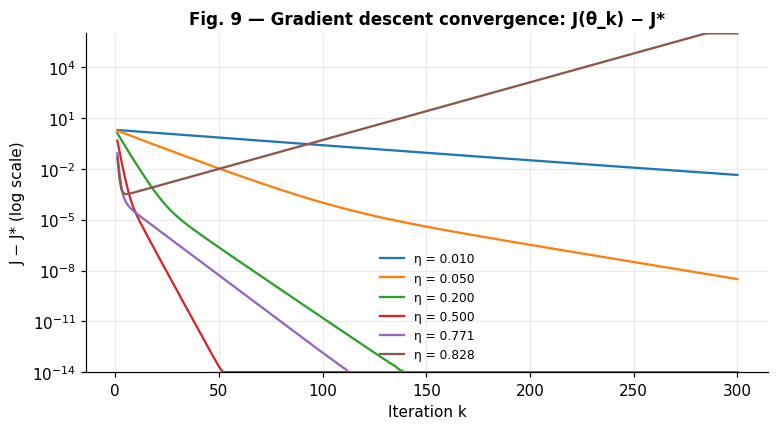

In [3]:
lr_max = max_stable_lr(s.X_train)
print(f"lambda_max(H) = {2/lr_max:.3f}  ->  theoretical maximum step 2/lambda_max = {lr_max:.3f}")
J_star = LinearRegressionScratch(solver="normal").fit(s.X_train, s.y_train).loss(s.X_train, s.y_train)
fig, ax = plt.subplots(figsize=(8, 4))
for lr in [0.01, 0.05, 0.2, 0.5, 0.95 * lr_max, 1.02 * lr_max]:
    m = LinearRegressionScratch(solver="gd", lr=lr, n_iter=300, tol=0)
    with np.errstate(all="ignore"):
        try:
            m.fit(s.X_train, s.y_train); lab = f"η = {lr:.3f}"
        except FloatingPointError:
            lab = f"η = {lr:.3f} (diverges)"
    h = np.array(m.loss_history_) - J_star
    ax.semilogy(np.arange(1, len(h) + 1), np.clip(h, 1e-14, 1e6), label=lab)
ax.set(title="Fig. 9 — Gradient descent convergence: J(θ_k) − J*", xlabel="Iteration k", ylabel="J − J* (log scale)", ylim=(1e-14, 1e6))
ax.legend(fontsize=8)
save(fig, "fig09_gd_convergence.png"); plt.show()

Convergence is **linear** (a straight line on a log scale), faster as $\eta$ approaches $1/\lambda_{\max}$; beyond $2/\lambda_{\max}$ the algorithm diverges, exactly as theory predicts. Conditioning is good because the variables are standardized (without standardization, $\lambda_{\max}$ would blow up because of log GDP per capita).

### 1.3 Three solvers, one solution

In [4]:
models = {
    "Normal equations": LinearRegressionScratch(solver="normal"),
    "Gradient descent": LinearRegressionScratch(solver="gd", lr=0.5, n_iter=10000, tol=1e-14),
    "SGD (B=64)": LinearRegressionScratch(solver="sgd", lr=0.05, n_iter=60, batch_size=64, decay=0.05),
}
coefs = {}
for name, m in models.items():
    t = time.perf_counter(); m.fit(s.X_train, s.y_train); dt = time.perf_counter() - t
    coefs[name] = np.append(m.intercept_, m.coef_)
    print(f"{name:22s} iterations/epochs = {m.n_iter_:5d}   time = {dt*1e3:7.1f} ms   J = {m.loss(s.X_train, s.y_train):.6f}")
C = pd.DataFrame(coefs, index=["bias"] + F)
print("max |GD - normal|  =", np.abs(C.iloc[:, 1] - C.iloc[:, 0]).max())
print("max |SGD - normal| =", np.abs(C.iloc[:, 2] - C.iloc[:, 0]).max())
C

Normal equations       iterations/epochs =     0   time =     0.8 ms   J = 11.842209
Gradient descent       iterations/epochs =    51   time =     6.3 ms   J = 11.842209


SGD (B=64)             iterations/epochs =    60   time =   205.3 ms   J = 11.843165
max |GD - normal|  = 1.7222742878728048e-07
max |SGD - normal| = 0.017198055757382757


,Normal equations,Gradient descent,SGD (B=64)
bias,3.755,3.755,3.743
log_dmg_climate_pct,-0.263,-0.263,-0.280
log_dmg_climate_pct_lag1,0.131,0.131,0.149
log_deaths_climate_pm,-0.097,-0.097,-0.108
log_affected_climate_pct,-0.031,-0.031,-0.038
n_hydro,0.230,0.230,0.229
n_meteo,0.077,0.077,0.062
n_climato,-0.036,-0.036,-0.033
log_dmg_geo_pct,-0.093,-0.093,-0.099
growth_lag1,1.809,1.809,1.797


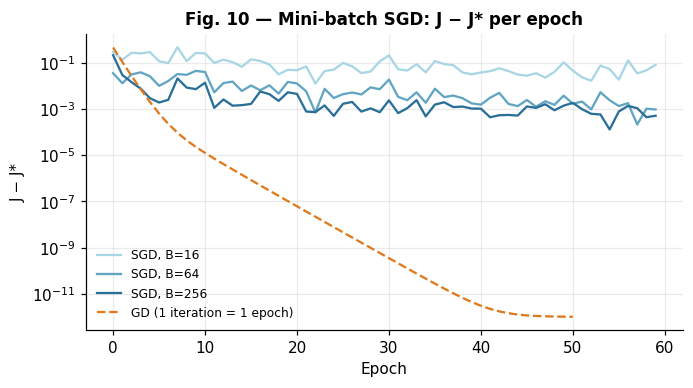

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for B, c in [(16, "#a9d6e5"), (64, "#61a5c2"), (256, "#2a6f97")]:
    m = LinearRegressionScratch(solver="sgd", lr=0.05, n_iter=60, batch_size=B, decay=0.05).fit(s.X_train, s.y_train)
    ax.semilogy(np.array(m.loss_history_) - J_star + 1e-12, color=c, label=f"SGD, B={B}")
ax.semilogy(np.array(models["Gradient descent"].loss_history_[:60]) - J_star + 1e-12, color=C_SKLEARN, ls="--", label="GD (1 iteration = 1 epoch)")
ax.set(title="Fig. 10 — Mini-batch SGD: J − J* per epoch", xlabel="Epoch", ylabel="J − J*")
ax.legend(fontsize=8); save(fig, "fig10_sgd.png"); plt.show()

SGD reaches a precision of about $10^{-3}$–$10^{-4}$ in a few epochs, then plateaus (stochastic gradient noise, which the decaying step reduces only slowly); full-batch GD reaches machine precision. With $n\approx5\,000$, GD is more than enough; SGD would pay off with millions of observations.

## 2. Choosing the regularization α (on validation)

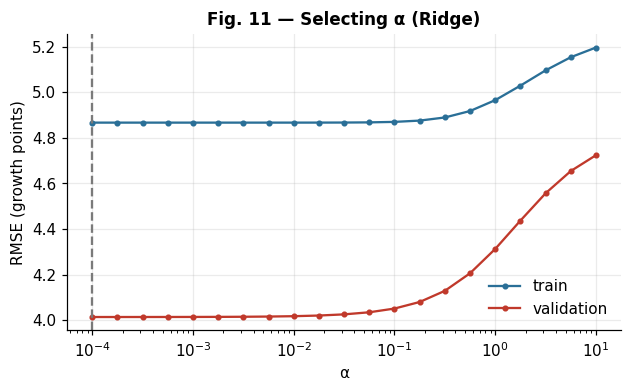

selected alpha = 0


In [6]:
alphas = np.r_[0, np.logspace(-4, 1, 21)]
rows = []
for a in alphas:
    m = LinearRegressionScratch(solver="normal", alpha=a).fit(s.X_train, s.y_train)
    rows.append((a, mean_squared_error(s.y_train, m.predict(s.X_train)) ** .5,
                 mean_squared_error(s.y_val, m.predict(s.X_val)) ** .5))
ridge = pd.DataFrame(rows, columns=["alpha", "rmse_train", "rmse_val"])
best_alpha = ridge.loc[ridge.rmse_val.idxmin(), "alpha"]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.semilogx(ridge.alpha[1:], ridge.rmse_train[1:], "o-", ms=3, label="train", color=C_SCRATCH)
ax.semilogx(ridge.alpha[1:], ridge.rmse_val[1:], "o-", ms=3, label="validation", color=C_ACCENT)
ax.axvline(max(best_alpha, 1e-4), color=C_NEUTRAL, ls="--")
ax.set(title="Fig. 11 — Selecting α (Ridge)", xlabel="α", ylabel="RMSE (growth points)"); ax.legend()
save(fig, "fig11_ridge_alpha.png"); plt.show()
print(f"selected alpha = {best_alpha:.4g}")

## 3. Final model: performance and naive baselines

In [7]:
lin = LinearRegressionScratch(solver="gd", alpha=best_alpha, lr=0.5, n_iter=10000, tol=1e-14).fit(s.X_train, s.y_train)
lag = F.index("growth_lag1")
def unstd_lag(X): return X[:, lag] * s.std[lag] + s.mean[lag]
def metrics(y, p): return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** .5, R2=r2_score(y, p))
rows = []
for split in ["train", "val", "test", "stress"]:
    X, y = getattr(s, f"X_{split}"), getattr(s, f"y_{split}")
    rows.append({"split": split, "model": "Training mean", **metrics(y, np.full_like(y, s.y_train.mean()))})
    rows.append({"split": split, "model": "Persistence (ŷ_t = y_{t-1})", **metrics(y, unstd_lag(X))})
    rows.append({"split": split, "model": "Linear from scratch", **metrics(y, lin.predict(X))})
perf = pd.DataFrame(rows).set_index(["split", "model"])
perf.to_csv("../results/linear_performance.csv"); perf

MAE   RMSE         R2
split  model                                               
train  Training mean                3.719  5.266  0.000e+00
       Persistence (ŷ_t = y_{t-1})  4.023  6.069 -3.283e-01
       Linear from scratch          3.348  4.867  1.459e-01
val    Training mean                3.553  4.835 -6.863e-05
       Persistence (ŷ_t = y_{t-1})  3.463  5.103 -1.142e-01
       Linear from scratch          2.818  4.014  3.107e-01
test   Training mean                2.531  3.671 -3.905e-02
       Persistence (ŷ_t = y_{t-1})  2.180  3.775 -9.888e-02
       Linear from scratch          1.973  3.130  2.443e-01
stress Training mean                8.357  9.657 -2.192e+00
       Persistence (ŷ_t = y_{t-1})  7.538  8.818 -1.661e+00
       Linear from scratch          5.241  6.653 -5.149e-01

## 4. What disasters add: ablation study
Under an identical protocol, we compare a **controls-only** model (persistence, level of development, global cycle) with the **controls + disasters** model. A lower out-of-sample error measures the *predictive* information carried by climate shocks. We also look at the subsample of country-years that were actually hit (damages > 0.1 % of GDP), where the effect should concentrate.

In [8]:
ctrl = [F.index(f) for f in dp.CONTROL_FEATURES]
m_ctrl = LinearRegressionScratch(solver="normal", alpha=best_alpha).fit(s.X_train[:, ctrl], s.y_train)
rows = []
for split in ["val", "test"]:
    X, y, fr = getattr(s, f"X_{split}"), getattr(s, f"y_{split}"), s.frames[split]
    hit = (fr.dmg_climate_pct > 0.1).to_numpy()
    for name, pred in [("controls only", m_ctrl.predict(X[:, ctrl])), ("controls + disasters", lin.predict(X))]:
        rows.append({"split": split, "model": name, "RMSE (all)": mean_squared_error(y, pred) ** .5,
                     "R2 (all)": r2_score(y, pred), "RMSE (hit)": mean_squared_error(y[hit], pred[hit]) ** .5,
                     "n hit": hit.sum()})
abl = pd.DataFrame(rows).set_index(["split", "model"])
abl.to_csv("../results/linear_ablation.csv"); abl

RMSE (all)  R2 (all)  RMSE (hit)  n hit
split model                                                        
val   controls only              4.052     0.298       3.191    145
      controls + disasters       4.014     0.311       2.999    145
test  controls only              3.157     0.232       3.080    152
      controls + disasters       3.130     0.244       2.807    152

## 5. Interpreting the coefficients and their uncertainty

Coefficients learned on standardized variables are converted back to original units ($\beta_j=w_j/\sigma_j$). Uncertainty is estimated with a **country-level bootstrap** (500 resamples of whole countries, implemented from scratch): it respects the within-country time dependence that classical OLS standard errors would ignore.

In [9]:
groups = s.frames["train"].ISO.to_numpy()
B = cluster_bootstrap_coefs(s.X_train, s.y_train, groups, alpha=best_alpha, n_boot=500, seed=SEED)
coef = pd.DataFrame({
    "beta (original units)": lin.coef_ / s.std,
    "CI95 low": np.percentile(B, 2.5, axis=0) / s.std,
    "CI95 high": np.percentile(B, 97.5, axis=0) / s.std,
    "w standardized": lin.coef_,
}, index=F)
coef["significant"] = (coef["CI95 low"] > 0) | (coef["CI95 high"] < 0)
coef.to_csv("../results/linear_coefficients.csv"); coef

,beta (original units),CI95 low,CI95 high,w standardized,significant
log_dmg_climate_pct,-0.644,-1.051,-0.261,-0.263,True
log_dmg_climate_pct_lag1,0.316,0.002,0.649,0.131,True
log_deaths_climate_pm,-0.109,-0.305,0.082,-0.097,False
log_affected_climate_pct,-0.044,-0.273,0.174,-0.031,False
n_hydro,0.187,0.036,0.316,0.230,True
n_meteo,0.054,-0.017,0.234,0.077,False
n_climato,-0.084,-0.438,0.271,-0.036,False
log_dmg_geo_pct,-0.531,-1.130,0.114,-0.093,False
growth_lag1,0.336,0.282,0.389,1.809,True
log_gdppc_lag1,-0.166,-0.270,-0.048,-0.256,True


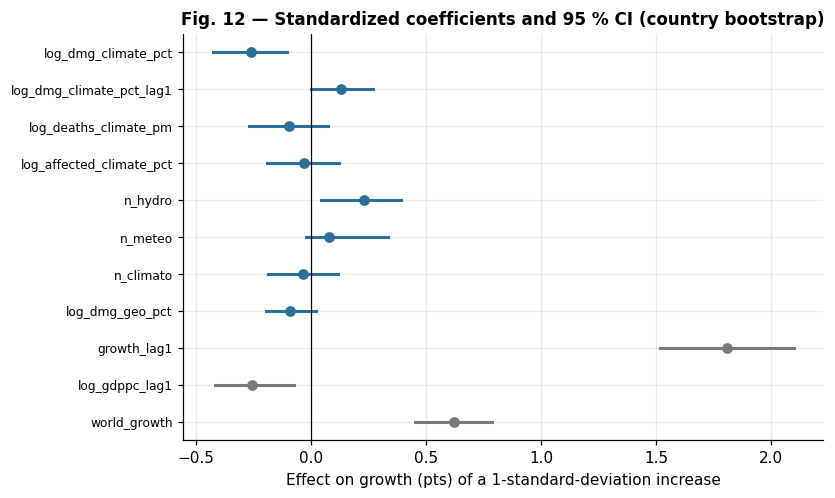

In [10]:
lo = np.percentile(B, 2.5, axis=0); hi = np.percentile(B, 97.5, axis=0)
order = np.arange(len(F))[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
colors = [C_CLIMATE if f in dp.DISASTER_FEATURES else C_NEUTRAL for f in F]
for k, j in enumerate(order):
    ax.plot([lo[j], hi[j]], [k, k], color=colors[j], lw=2)
    ax.plot(lin.coef_[j], k, "o", color=colors[j])
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(F))); ax.set_yticklabels([F[j] for j in order], fontsize=8)
ax.set(title="Fig. 12 — Standardized coefficients and 95 % CI (country bootstrap)",
       xlabel="Effect on growth (pts) of a 1-standard-deviation increase")
save(fig, "fig12_coefficients.png"); plt.show()

In [11]:
j0, j1 = F.index("log_dmg_climate_pct"), F.index("log_dmg_climate_pct_lag1")
b0, b1 = lin.coef_[j0] / s.std[j0], lin.coef_[j1] / s.std[j1]
B0, B1 = B[:, j0] / s.std[j0], B[:, j1] / s.std[j1]
rows = []
for d in [0.5, 1, 5, 10, 50]:
    x = np.log1p(d)
    rows.append({"damages (% GDP)": d, "effect year t (pts)": b0 * x,
                 "CI95 t": f"[{np.percentile(B0*x,2.5):.2f}, {np.percentile(B0*x,97.5):.2f}]",
                 "effect t+1 (pts)": b1 * x, "cumulative effect t, t+1": (b0 + b1) * x,
                 "CI95 cumulative": f"[{np.percentile((B0+B1)*x,2.5):.2f}, {np.percentile((B0+B1)*x,97.5):.2f}]"})
eff = pd.DataFrame(rows); eff.to_csv("../results/linear_effects.csv", index=False); eff

,damages (% GDP),effect year t (pts),CI95 t,effect t+1 (pts),"cumulative effect t, t+1",CI95 cumulative
0,0.5,-0.261,"[-0.43, -0.11]",0.128,-0.133,"[-0.30, 0.04]"
1,1.0,-0.447,"[-0.73, -0.18]",0.219,-0.228,"[-0.52, 0.06]"
2,5.0,-1.155,"[-1.88, -0.47]",0.566,-0.589,"[-1.35, 0.16]"
3,10.0,-1.545,"[-2.52, -0.63]",0.757,-0.788,"[-1.80, 0.22]"
4,50.0,-2.534,"[-4.13, -1.03]",1.242,-1.293,"[-2.95, 0.35]"


**Reading.** A climate shock causing damages equal to 10 % of GDP is associated, all else equal, with growth about 1.5 points lower in the shock year, followed by a partial rebound the next year (reconstruction). The two-year cumulative effect remains negative but is more uncertain. The *count* variables (number of floods, storms) have small or positive coefficients: they capture country size and recording quality rather than shock intensity.

## 6. Residual diagnostics

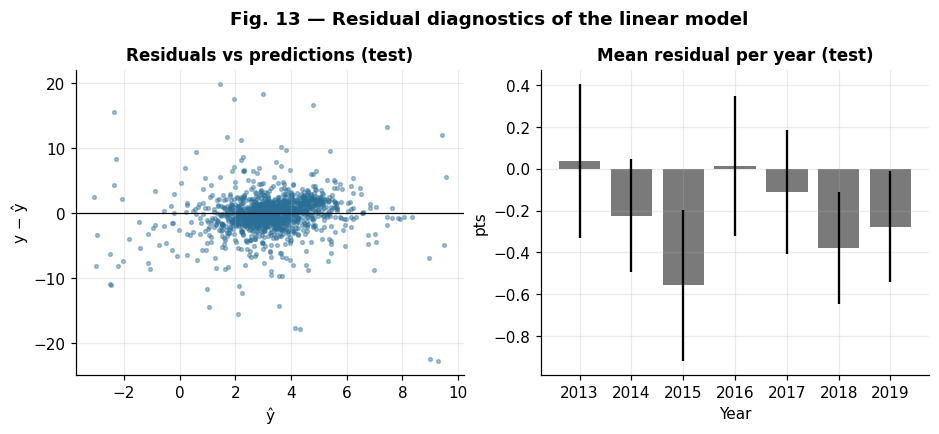

In [12]:
pred = lin.predict(s.X_test); res = s.y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(pred, res, s=6, alpha=0.4, color=C_SCRATCH); axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(title="Residuals vs predictions (test)", xlabel="ŷ", ylabel="y − ŷ")
yr = s.frames["test"].assign(res=res).groupby("year").res.agg(["mean", "std"])
axes[1].bar(yr.index, yr["mean"], yerr=yr["std"] / 10, color=C_NEUTRAL)
axes[1].set(title="Mean residual per year (test)", xlabel="Year", ylabel="pts")
fig.suptitle("Fig. 13 — Residual diagnostics of the linear model", fontweight="bold", y=1.03)
save(fig, "fig13_residuals.png"); plt.show()

Residuals are centred but **heteroscedastic**: the variance is much larger for volatile economies (small countries, commodity exporters). The model underestimates deep recessions, which mostly come from non-climate shocks (financial crises, conflicts, oil prices).